![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# Deep Learning and Computer Vision
*Data Science & Machine Learning - Week 5, Day 4*

## How to use this notebook

Every model this week works on a table: one row per customer, one column per feature. Today adds a new family, **neural networks**, which can learn from tables too, but are at their best on images, sound and text, where the features are not given and have to be learnt from raw pixels or words.

The plan for the day:

+ What a neural network is, starting from logistic regression, and how to build and train one with **Keras**.
+ How training works and how to stop a network from overfitting.
+ How images become numbers, and why **convolutional neural networks** (CNNs) suit them.
+ **Transfer learning**: reusing a network trained on millions of photos when you only have a few hundred of your own.

The slides **0. Deep Learning** and **3. Gradient Descent** in this folder go with the notebook. **Download or clone the whole `s-507` folder**: it reads `churn.csv` and the `images/` folder. The first run also downloads the Fashion-MNIST images (30 MB) and the MobileNetV2 weights (9 MB); Keras keeps a copy, so later runs are offline. Training cells take from a few seconds to about two minutes on a laptop.

## Table of contents

- [Setup](#Setup)
- [1. From logistic regression to a neural network](#1.-From-logistic-regression-to-a-neural-network)
    - [One neuron](#One-neuron)
    - [Why hidden layers matter](#Why-hidden-layers-matter)
- [2. A neural network on tabular data](#2.-A-neural-network-on-tabular-data)
    - [Same churn data, same split](#Same-churn-data,-same-split)
    - [Training curves](#Training-curves)
- [3. Training a network](#3.-Training-a-network)
    - [Gradient descent, batches and epochs](#Gradient-descent,-batches-and-epochs)
    - [The learning rate](#The-learning-rate)
    - [Dropout and early stopping](#Dropout-and-early-stopping)
    - [Where neural networks stand on tables](#Where-neural-networks-stand-on-tables)
- [4. Images as data](#4.-Images-as-data)
    - [Fashion-MNIST](#Fashion-MNIST)
    - [A dense network on pixels](#A-dense-network-on-pixels)
    - [Convolution: a filter that slides](#Convolution:-a-filter-that-slides)
- [5. Convolutional neural networks](#5.-Convolutional-neural-networks)
    - [A small CNN](#A-small-CNN)
    - [Which mistakes does it make?](#Which-mistakes-does-it-make?)
    - [What the first layer learnt](#What-the-first-layer-learnt)
- [6. Transfer learning](#6.-Transfer-learning)
    - [The problem: few labelled images](#The-problem:-few-labelled-images)
    - [The idea: reuse a network trained on millions of photos](#The-idea:-reuse-a-network-trained-on-millions-of-photos)
- [Summary: what to use when](#Summary:-what-to-use-when)
- [Appendix](#Appendix)
    - [A.1 Gradient descent by hand](#A.1-Gradient-descent-by-hand)
    - [A.2 Classical image processing with OpenCV](#A.2-Classical-image-processing-with-OpenCV)
    - [A.3 The same models in PyTorch](#A.3-The-same-models-in-PyTorch)

## Setup

In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # hide TensorFlow's start-up messages

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
import cv2

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.cluster import KMeans
from sklearn.metrics import f1_score, confusion_matrix, ConfusionMatrixDisplay

tf.config.experimental.enable_op_determinism()
print("TensorFlow", tf.__version__, "- Keras", keras.__version__)

TensorFlow 2.21.0 - Keras 3.15.1


`enable_op_determinism` and the `keras.utils.set_random_seed(0)` calls before each model make the results repeatable. A network starts from random weights, so without them every run gives slightly different numbers.

## 1. From logistic regression to a neural network

### One neuron

You already know a neural network with one neuron: **logistic regression**. It multiplies each feature by a weight, adds them up with a bias, and passes the sum through the sigmoid function to get a probability.

![Logistic regression as a single neuron](images/NeuralNetwork.png)

A **neural network** connects many of these units in **layers**. Each unit in a **hidden layer** takes a weighted sum of the previous layer's outputs and applies an **activation function**. The last layer produces the prediction. The weights are what the network learns.

The activation is what makes layers worth stacking. Without it, a layer of weighted sums followed by another layer of weighted sums is still one weighted sum: a linear model, however many layers you add.

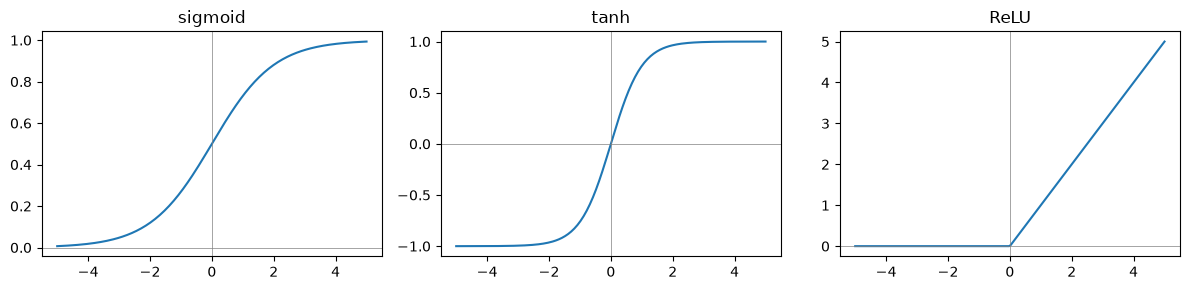

In [2]:
z = np.linspace(-5, 5, 200)
activations = {
    "sigmoid": 1 / (1 + np.exp(-z)),
    "tanh": np.tanh(z),
    "ReLU": np.maximum(0, z),
}
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, (name, values) in zip(axes, activations.items()):
    ax.plot(z, values)
    ax.axhline(0, color="grey", linewidth=0.5)
    ax.axvline(0, color="grey", linewidth=0.5)
    ax.set_title(name)
plt.tight_layout()
plt.show()

+ **ReLU** (`max(0, z)`) is the default for hidden layers: cheap to compute and it trains well.
+ **Sigmoid** squeezes any number into 0-1, so it is used in the output layer for a **binary** prediction.
+ **Softmax** (not plotted) turns the outputs of several units into probabilities that add up to 1, so it is used in the output layer for **multiclass** predictions.

### Why hidden layers matter

The two moons from Day 2 again: no straight line separates them, so logistic regression cannot do well.

In [3]:
X_moons, y_moons = make_moons(n_samples=500, noise=0.25, random_state=0)
Xm_train, Xm_test, ym_train, ym_test = train_test_split(X_moons, y_moons, test_size=0.3, random_state=0)

logreg = LogisticRegression().fit(Xm_train, ym_train)
print("Logistic regression test accuracy:", round(logreg.score(Xm_test, ym_test), 3))

Logistic regression test accuracy: 0.827


Now a small network in **Keras**, the deep-learning library that ships with TensorFlow. Every Keras model follows the same four steps:

1. **Define** the layers. `keras.Sequential` stacks them in order; `keras.Input` declares the shape of one row; `Dense(units, activation=...)` is a layer where every unit is connected to every input.
2. **Compile**: choose the optimizer (how weights are updated), the loss (what is minimised) and the metrics to report.
3. **Fit** on the training data for a number of **epochs** (full passes over the data).
4. **Evaluate** or **predict** on new data.

In [4]:
keras.utils.set_random_seed(0)
net = keras.Sequential([
    keras.Input(shape=(2,)),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(1, activation="sigmoid"),
])
net.compile(optimizer=keras.optimizers.Adam(learning_rate=0.01), loss="binary_crossentropy", metrics=["accuracy"])
net.fit(Xm_train, ym_train, epochs=200, verbose=0)

loss, accuracy = net.evaluate(Xm_test, ym_test, verbose=0)
print("Neural network test accuracy:", round(accuracy, 3))

Neural network test accuracy: 0.92


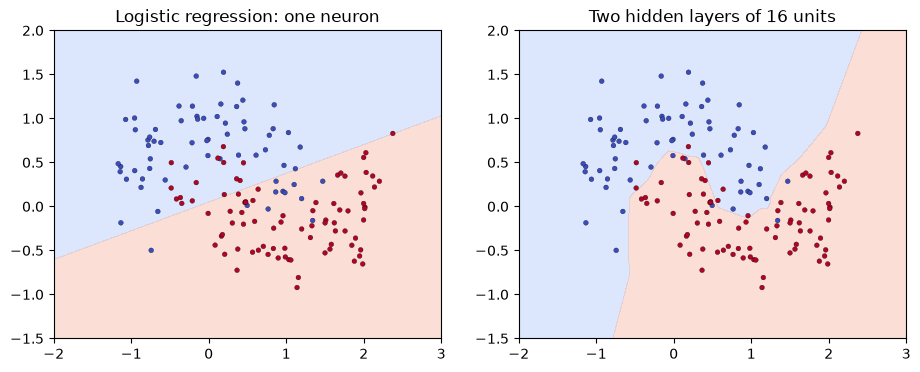

In [5]:
def plot_boundary(predict, X, y, ax, title):
    xx, yy = np.meshgrid(np.linspace(-2, 3, 200), np.linspace(-1.5, 2, 200))
    probabilities = predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, probabilities, levels=[0, 0.5, 1], alpha=0.3, cmap="coolwarm")
    ax.scatter(X[:, 0], X[:, 1], c=y, s=12, cmap="coolwarm", edgecolor="k", linewidth=0.2)
    ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
plot_boundary(lambda g: logreg.predict_proba(g)[:, 1], Xm_test, ym_test, axes[0], "Logistic regression: one neuron")
plot_boundary(lambda g: net.predict(g, verbose=0).ravel(), Xm_test, ym_test, axes[1], "Two hidden layers of 16 units")
plt.show()

Logistic regression scores 0.827 with its straight line; the network scores 0.92. The hidden layers let the network bend its boundary around the moons, like the trees did on Day 2, but with a smooth curve instead of steps.

The output layer and the loss go together:

| Task | Output layer | Loss |
|---|---|---|
| Binary classification | `Dense(1, activation="sigmoid")` | `"binary_crossentropy"` |
| Multiclass, labels 0, 1, 2, ... | `Dense(n_classes, activation="softmax")` | `"sparse_categorical_crossentropy"` |
| Regression | `Dense(1)` with no activation | `"mse"` |

## 2. A neural network on tabular data

### Same churn data, same split

The churn data and split from Week 4 Day 5 and Day 2, so the network can be compared with the trees and ensembles.

Networks are trained by gradient descent, so, like KNN and logistic regression, they need **scaled** features. The scaler is fitted on the training rows only.

In [6]:
churn = pd.read_csv("churn.csv")
y = (churn["Churn?"] == "True.").astype(int)
X = churn.drop(columns=["State", "Phone", "Churn?"])
for col in ["Int'l Plan", "VMail Plan"]:
    X[col] = (X[col] == "yes").astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
scaler = StandardScaler().fit(X_train)
X_train_s, X_test_s = scaler.transform(X_train), scaler.transform(X_test)
print(X_train_s.shape[0], "training rows,", X_train_s.shape[1], "features")

2499 training rows, 18 features


In [7]:
def churn_model(dropout=0.0, learning_rate=0.001):
    keras.utils.set_random_seed(0)
    layers = [keras.Input(shape=(X_train_s.shape[1],)), keras.layers.Dense(32, activation="relu")]
    if dropout:
        layers.append(keras.layers.Dropout(dropout))
    layers.append(keras.layers.Dense(16, activation="relu"))
    if dropout:
        layers.append(keras.layers.Dropout(dropout))
    layers.append(keras.layers.Dense(1, activation="sigmoid"))
    model = keras.Sequential(layers)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate), loss="binary_crossentropy", metrics=["accuracy"])
    return model

model = churn_model()
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │           608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,153 (4.50 KB)

 Trainable params: 1,153 (4.50 KB)

 Non-trainable params: 0 (0.00 B)

The **parameters** are the weights and biases the network will learn. The first layer has 18 inputs × 32 units + 32 biases = 608, the second 32 × 16 + 16 = 528, and the output 16 + 1 = 17: 1,153 in total, from 2,499 training rows.

### Training curves

`validation_split=0.2` keeps the last 20% of the training rows aside, and Keras reports the loss on them after every epoch. The **history** returned by `fit` holds both curves.

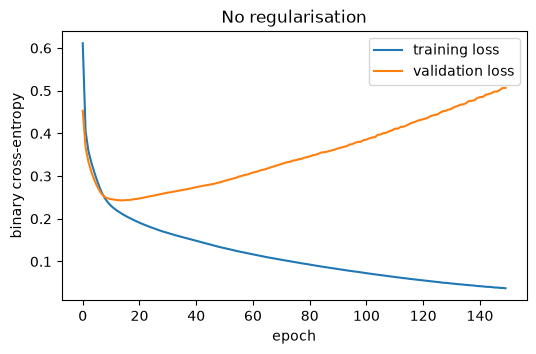

Lowest validation loss at epoch 15 - 0.243
Validation loss after 150 epochs: 0.507


In [8]:
history = model.fit(X_train_s, y_train, epochs=150, batch_size=32, validation_split=0.2, verbose=0)

def plot_history(history, title):
    plt.figure(figsize=(6, 3.5))
    plt.plot(history.history["loss"], label="training loss")
    plt.plot(history.history["val_loss"], label="validation loss")
    plt.xlabel("epoch")
    plt.ylabel("binary cross-entropy")
    plt.title(title)
    plt.legend()
    plt.show()

plot_history(history, "No regularisation")
best_epoch = int(np.argmin(history.history["val_loss"])) + 1
print("Lowest validation loss at epoch", best_epoch, "-", round(min(history.history["val_loss"]), 3))
print("Validation loss after 150 epochs:", round(history.history["val_loss"][-1], 3))

This is the overfitting picture from Day 1's validation curve, drawn over training time instead of model complexity. The training loss keeps falling, because the network is memorising the training rows. The validation loss stops improving after 15 epochs and then climbs: from there on, every epoch makes the model worse on new customers.

In [9]:
y_pred = (model.predict(X_test_s, verbose=0).ravel() >= 0.5).astype(int)
print("Test F1 after 150 epochs:", round(f1_score(y_test, y_pred), 3))

Test F1 after 150 epochs: 0.675


0.675: worse than the single decision tree from Week 4 Day 5 (0.739). Two fixes come next: train for the right number of epochs, and make memorising harder.

## 3. Training a network

### Gradient descent, batches and epochs

The weights start random. Training repeats three steps:

1. Run a **batch** of rows through the network and compute the loss.
2. Compute the **gradient**: for every weight, which direction makes the loss go down. **Backpropagation** is the algorithm that does this efficiently, layer by layer from the output back.
3. Move every weight a small step in that direction. The size of the step is the **learning rate**.

With `batch_size=32`, the weights are updated after every 32 rows; an **epoch** is one pass through all the training rows, so here about 63 updates per epoch. **Adam**, the optimizer used today, adapts the step size for each weight as training goes, which is why it is the usual default. The appendix runs gradient descent by hand on a straight line.

### The learning rate

learning rate 0.1      lowest validation loss 0.297 at epoch 1, after 50 epochs 0.327


learning rate 0.001    lowest validation loss 0.243 at epoch 15, after 50 epochs 0.287


learning rate 1e-05    lowest validation loss 0.595 at epoch 50, after 50 epochs 0.595


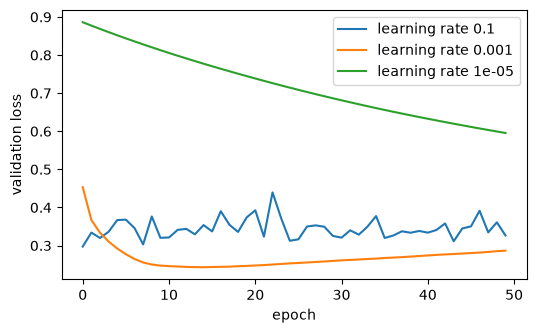

In [10]:
plt.figure(figsize=(6, 3.5))
for learning_rate in [0.1, 0.001, 0.00001]:
    h = churn_model(learning_rate=learning_rate).fit(X_train_s, y_train, epochs=50, batch_size=32, validation_split=0.2, verbose=0)
    val_loss = h.history["val_loss"]
    plt.plot(val_loss, label=f"learning rate {learning_rate}")
    print(f"learning rate {learning_rate:<8} lowest validation loss {min(val_loss):.3f} at epoch {int(np.argmin(val_loss)) + 1}, after 50 epochs {val_loss[-1]:.3f}")
plt.xlabel("epoch")
plt.ylabel("validation loss")
plt.legend()
plt.show()

With 0.1 the steps are too big: the validation loss is lowest after the very first epoch (0.297) and never gets back there. With 0.00001 they are too small: after 50 epochs the loss (0.595) has barely moved. 0.001 reaches 0.243 at epoch 15. Adam's default, 0.001, is a good place to start; change it only if the curves look like one of the other two.

### Dropout and early stopping

+ **Dropout** switches off a random share of the units at every training step (here 30%), so the network cannot rely on any single unit to memorise a row. At prediction time all units are used.
+ **Early stopping** watches the validation loss and stops training when it has not improved for `patience` epochs. `restore_best_weights=True` then rolls the weights back to the best epoch. You can set a large number of epochs and let the validation data decide.

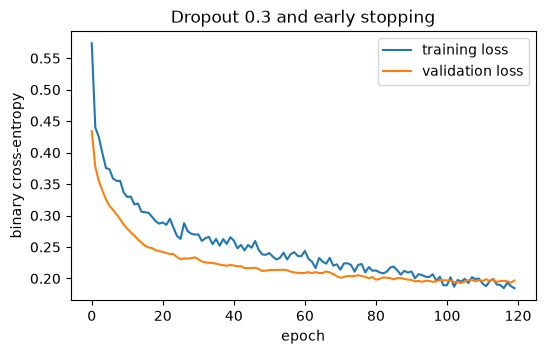

Stopped after 120 epochs; best epoch 105
Test F1: 0.816


In [11]:
model = churn_model(dropout=0.3)
early_stopping = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
history = model.fit(X_train_s, y_train, epochs=500, batch_size=32, validation_split=0.2, callbacks=[early_stopping], verbose=0)

plot_history(history, "Dropout 0.3 and early stopping")
print("Stopped after", len(history.history["loss"]), "epochs; best epoch", int(np.argmin(history.history["val_loss"])) + 1)
y_pred = (model.predict(X_test_s, verbose=0).ravel() >= 0.5).astype(int)
print("Test F1:", round(f1_score(y_test, y_pred), 3))

Training ran for 120 epochs and kept the weights from epoch 105, where the validation loss was lowest. Dropout slowed the overfitting down: the best epoch comes much later than the 15 without it, and the test F1 rises from 0.675 to 0.816.

### Where neural networks stand on tables

The same test set, with the results from Week 4 Day 5 and Day 2:

| Model | Test F1 |
|---|---|
| Decision tree (Week 4 Day 5) | 0.739 |
| Neural network, 150 epochs | 0.675 |
| Neural network, dropout and early stopping | 0.816 |
| Random forest (Day 2) | 0.876 |
| HistGradientBoosting (Day 2) | 0.892 |

On tabular data like this, **gradient-boosted trees usually win**, and they need no scaling and much less tuning. Neural networks earn their place when the raw input is pixels, sound or words, where nobody can hand them good features. That is the rest of the day.

## 4. Images as data

### Fashion-MNIST

70,000 small grayscale photos of clothes in 10 classes, built into Keras: 60,000 for training and 10,000 for testing.

training images: (60000, 28, 28) test images: (10000, 28, 28) pixel values from 0 to 255


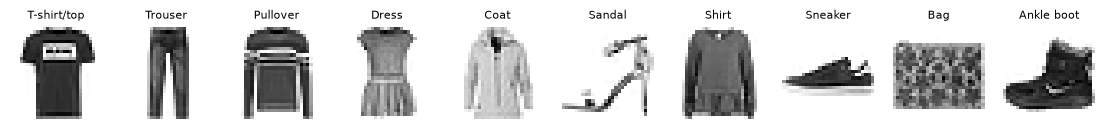

In [12]:
(x_train, y_train_img), (x_test, y_test_img) = keras.datasets.fashion_mnist.load_data()
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
print("training images:", x_train.shape, "test images:", x_test.shape, "pixel values from", x_train.min(), "to", x_train.max())

fig, axes = plt.subplots(1, 10, figsize=(14, 2))
for label, ax in enumerate(axes):
    ax.imshow(x_train[y_train_img == label][0], cmap="gray_r")
    ax.set_title(class_names[label], fontsize=8)
    ax.axis("off")
plt.show()

To a computer, a grayscale image is a table of numbers: one per pixel, from 0 (black) to 255 (white). Here is a 6 × 6 patch from the middle of the first training image, an ankle boot.

In [13]:
print(x_train[0, 18:24, 14:20])

[[150 255 229 221 188 154]
 [ 65  73 106 117 168 219]
 [240 195 227 245 239 223]
 [220 236 225 216 199 206]
 [200 196 194 191 195 191]
 [193 198 204 209 210 210]]


A colour image has three such tables, one per channel (red, green, blue), so its shape is `(height, width, 3)`.

### A dense network on pixels

The simplest approach: flatten each 28 × 28 image into 784 numbers and use the same kind of network as for churn. `Rescaling(1/255)` scales the pixels to 0-1 inside the model, and `Flatten` turns the grid into one long row.

In [14]:
keras.utils.set_random_seed(0)
dense_net = keras.Sequential([
    keras.Input(shape=(28, 28)),
    keras.layers.Rescaling(1 / 255),
    keras.layers.Flatten(),
    keras.layers.Dense(128, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])
dense_net.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
dense_net.fit(x_train, y_train_img, epochs=10, batch_size=128, validation_split=0.1, verbose=0)

dense_accuracy = dense_net.evaluate(x_test, y_test_img, verbose=0)[1]
print("Parameters:", f"{dense_net.count_params():,}", "- test accuracy:", round(dense_accuracy, 3))

Parameters: 101,770 - test accuracy: 0.881


88.1% of the test images are classified correctly, with 101,770 parameters. But flattening throws away the layout: the network does not know that pixel 100 sits right next to pixel 101. It would have to learn "a sleeve" separately for every position in the image.

### Convolution: a filter that slides

A **convolution** slides a small grid of weights (a **filter** or **kernel**, here 3 × 3) across the image. At every position it multiplies the filter by the patch of pixels under it and adds up the result. The output is a **feature map** that is high wherever the patch looks like the filter.

Two hand-made filters: one responds to vertical edges (dark on the left, light on the right), the other to horizontal edges.

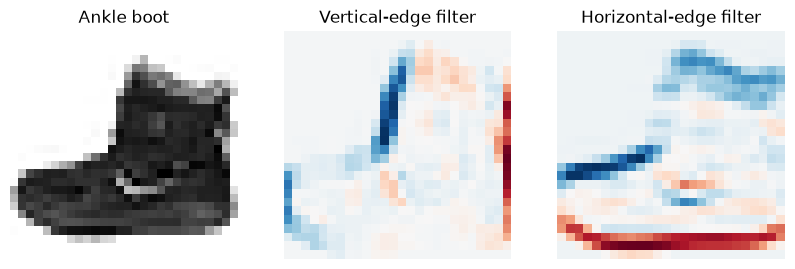

In [15]:
def convolve(image, kernel):
    h, w = image.shape
    out = np.zeros((h - 2, w - 2))
    for i in range(h - 2):
        for j in range(w - 2):
            out[i, j] = (image[i:i + 3, j:j + 3] * kernel).sum()
    return out

vertical_edges = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]])
horizontal_edges = vertical_edges.T

image = x_train[y_train_img == 9][0] / 255
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
for ax, (title, picture) in zip(axes, [("Ankle boot", image),
                                       ("Vertical-edge filter", convolve(image, vertical_edges)),
                                       ("Horizontal-edge filter", convolve(image, horizontal_edges))]):
    ax.imshow(picture, cmap="gray_r" if title == "Ankle boot" else "RdBu")
    ax.set_title(title)
    ax.axis("off")
plt.show()

The same filter is used at every position, so a pattern is recognised wherever it appears, with only 9 weights.

A **convolutional layer** learns its own filters instead of using hand-made ones: `Conv2D(32, 3)` learns 32 filters of 3 × 3. Two more ideas complete a CNN:

+ **Pooling** (`MaxPooling2D()`) keeps the largest value in every 2 × 2 block. The feature map halves in size and small shifts in position stop mattering.
+ **Stacking**: the first layer finds edges, the next combines edges into shapes such as a collar or a heel, and the last dense layer turns those shapes into a class.

## 5. Convolutional neural networks

### A small CNN

Two convolution-and-pooling blocks, then the classifier. `Conv2D` expects a channel dimension, so the images get shape `(28, 28, 1)`.

In [16]:
def make_cnn():
    keras.utils.set_random_seed(0)
    model = keras.Sequential([
        keras.Input(shape=(28, 28, 1)),
        keras.layers.Rescaling(1 / 255),
        keras.layers.Conv2D(32, 3, activation="relu"),
        keras.layers.MaxPooling2D(),
        keras.layers.Conv2D(64, 3, activation="relu"),
        keras.layers.MaxPooling2D(),
        keras.layers.Flatten(),
        keras.layers.Dropout(0.5),
        keras.layers.Dense(10, activation="softmax"),
    ])
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

cnn = make_cnn()
cnn.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 10)             │        16,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,826 (136.04 KB)

 Trainable params: 34,826 (136.04 KB)

 Non-trainable params: 0 (0.00 B)

Read the output shapes from top to bottom: 28 × 28 images become 32 feature maps of 26 × 26 (a 3 × 3 filter cannot be centred on the border pixels), pooling halves them to 13 × 13, and so on. The CNN has about a third of the dense network's parameters.

This cell trains on all 60,000 images and takes a minute or two.

In [17]:
history = cnn.fit(x_train[..., None], y_train_img, epochs=10, batch_size=128, validation_split=0.1, verbose=0)
cnn_accuracy = cnn.evaluate(x_test[..., None], y_test_img, verbose=0)[1]
print("Validation accuracy by epoch:", [round(a, 3) for a in history.history["val_accuracy"]])
print("CNN test accuracy:", round(cnn_accuracy, 3), "- dense network:", round(dense_accuracy, 3))

Validation accuracy by epoch: [0.84, 0.862, 0.874, 0.875, 0.881, 0.886, 0.891, 0.895, 0.897, 0.902]
CNN test accuracy: 0.895 - dense network: 0.881


The CNN reaches 0.895 against 0.881 for the dense network, with 34,826 parameters instead of 101,770. The validation accuracy is still rising at epoch 10, so a few more epochs would help a little.

### Which mistakes does it make?

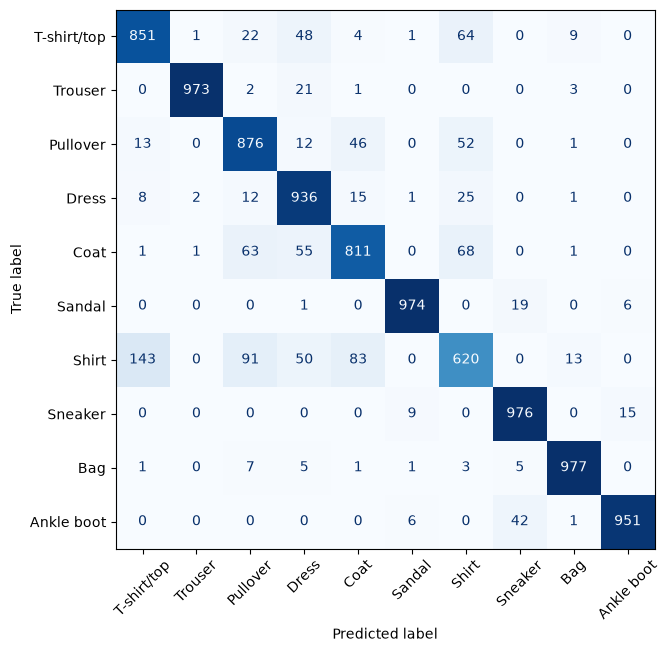

143 shirts predicted as T-shirt/top


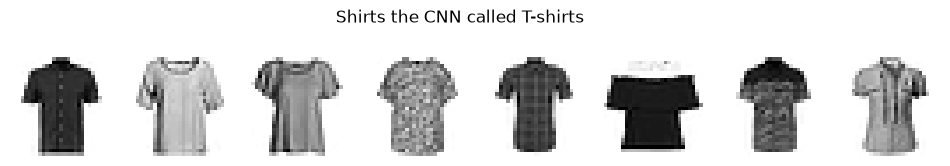

In [18]:
cnn_pred = cnn.predict(x_test[..., None], verbose=0).argmax(axis=1)
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(confusion_matrix(y_test_img, cnn_pred), display_labels=class_names).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
plt.show()

shirts_as_tshirts = np.where((y_test_img == 6) & (cnn_pred == 0))[0]
print(len(shirts_as_tshirts), "shirts predicted as T-shirt/top")
fig, axes = plt.subplots(1, 8, figsize=(12, 2))
for ax, i in zip(axes, shirts_as_tshirts):
    ax.imshow(x_test[i], cmap="gray_r")
    ax.axis("off")
plt.suptitle("Shirts the CNN called T-shirts")
plt.show()

The largest single mistake is 143 shirts predicted as T-shirts, and many of them would fool a person too. Most errors are between the upper-body classes (T-shirt, pullover, coat, shirt), which look alike at 28 × 28 pixels; trousers, bags and footwear are almost never confused. As with any classifier, the confusion matrix tells you where to look next: more examples of the hard classes, or larger images.

### What the first layer learnt

Each of the 32 filters of the first convolutional layer produces its own feature map. Looking at a few of them for one image shows what the network chose to detect.

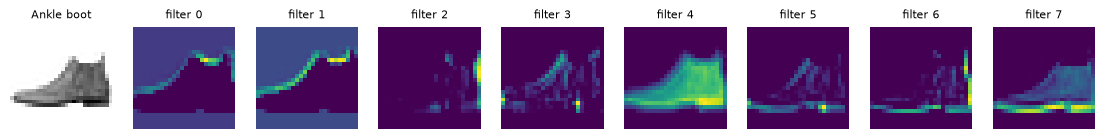

In [19]:
first_layer = keras.Model(inputs=cnn.inputs, outputs=cnn.layers[1].output)
maps = first_layer.predict(x_test[:1, ..., None], verbose=0)[0]

fig, axes = plt.subplots(1, 9, figsize=(14, 2))
axes[0].imshow(x_test[0], cmap="gray_r")
axes[0].set_title(class_names[y_test_img[0]], fontsize=8)
for k, ax in enumerate(axes[1:]):
    ax.imshow(maps[:, :, k], cmap="viridis")
    ax.set_title(f"filter {k}", fontsize=8)
for ax in axes:
    ax.axis("off")
plt.show()

Some maps light up on edges in one direction, some on the whole shape, some on the background. Nobody designed these filters: they were learnt because they help reduce the loss.

## 6. Transfer learning

### The problem: few labelled images

Real projects rarely have 60,000 labelled images. Suppose you only have **1,000**. A CNN trained from scratch on them has little to learn from.

In [20]:
rng = np.random.default_rng(0)
small = rng.choice(len(x_train), 1000, replace=False)
x_small, y_small = x_train[small], y_train_img[small]
x_eval, y_eval = x_test[:2000], y_test_img[:2000]

def early_stopping():
    return keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)

scratch = make_cnn()
scratch.fit(x_small[..., None], y_small, epochs=100, batch_size=32, validation_split=0.2, callbacks=[early_stopping()], verbose=0)
scratch_accuracy = scratch.evaluate(x_eval[..., None], y_eval, verbose=0)[1]
print("CNN from scratch on 1,000 images, accuracy on 2,000 test images:", round(scratch_accuracy, 3))

CNN from scratch on 1,000 images, accuracy on 2,000 test images: 0.801


### The idea: reuse a network trained on millions of photos

Networks such as **MobileNetV2**, ResNet or EfficientNet were trained on **ImageNet**: 1.4 million photos in 1,000 classes. Their convolutional layers learnt general-purpose filters (edges, textures, parts of objects) that are useful for almost any image. **Transfer learning** keeps those layers, **freezes** them so their weights do not change, and trains only a new output layer for your classes.

MobileNetV2 expects colour images of at least 32 × 32 pixels, so each grayscale image is copied into three channels and resized to 96 × 96. `include_top=False` drops ImageNet's 1,000-class output layer, and `pooling="avg"` turns the last feature maps into one vector of 1,280 numbers per image.

In [21]:
def to_rgb_96(images):
    rgb = np.repeat(images[..., None], 3, axis=-1).astype("float32")
    return tf.image.resize(rgb, (96, 96)).numpy()

x_small_96, x_eval_96 = to_rgb_96(x_small), to_rgb_96(x_eval)

keras.utils.set_random_seed(0)
base = keras.applications.MobileNetV2(input_shape=(96, 96, 3), include_top=False, weights="imagenet", pooling="avg")
base.trainable = False

inputs = keras.Input(shape=(96, 96, 3))
features = base(keras.applications.mobilenet_v2.preprocess_input(inputs), training=False)
outputs = keras.layers.Dense(10, activation="softmax")(keras.layers.Dropout(0.3)(features))
transfer = keras.Model(inputs, outputs)
transfer.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

trainable = sum(int(np.prod(w.shape)) for w in transfer.trainable_weights)
print(f"Total parameters: {transfer.count_params():,} - trainable: {trainable:,}")

Total parameters: 2,270,794 - trainable: 12,810


Only the new output layer is trained: 1,280 features × 10 classes + 10 biases. The 2.2 million frozen weights are used as they are. This model uses the **functional API**, where each layer is called on the output of the previous one. It does the same as `Sequential`, but allows steps such as the preprocessing function in the middle.

This cell takes under a minute.

In [22]:
transfer.fit(x_small_96, y_small, epochs=50, batch_size=32, validation_split=0.2, callbacks=[early_stopping()], verbose=0)
transfer_accuracy = transfer.evaluate(x_eval_96, y_eval, verbose=0)[1]

print(f"{'CNN from scratch, 1,000 images':<38} {scratch_accuracy:.3f}")
print(f"{'MobileNetV2 transfer, 1,000 images':<38} {transfer_accuracy:.3f}")
print(f"{'CNN from scratch, 60,000 images':<38} {cnn.evaluate(x_eval[..., None], y_eval, verbose=0)[1]:.3f}")

CNN from scratch, 1,000 images         0.801
MobileNetV2 transfer, 1,000 images     0.834
CNN from scratch, 60,000 images        0.899


With the same 1,000 images, the pretrained network scores 0.834 against 0.801 for the CNN trained from scratch. The CNN trained on all 60,000 images still does best, with 0.899 on these 2,000 test images.

+ With **few labelled images**, start from a pretrained network. It is also far cheaper: we trained 12,810 weights instead of tens of thousands.
+ With **plenty of data**, a network trained for your images can catch up and overtake, as the 60,000-image CNN does here. ImageNet is colour photos of everyday objects, not tiny grayscale clothes, so its filters are a good start rather than a perfect fit.
+ The usual next step is **fine-tuning**: once the new head is trained, unfreeze the last few layers of the base and keep training with a very small learning rate (for example `1e-5`), so the pretrained filters adapt to your images without being destroyed. It needs a GPU to be practical on large images.
+ For your own photos, put them in one folder per class and load them with `keras.utils.image_dataset_from_directory`; the rest of this section stays the same.

## Summary: what to use when

| Data | Start with | Why |
|---|---|---|
| A table of features | Gradient-boosted trees, random forest, logistic regression | Better results with less tuning; no scaling needed for trees |
| Images, many labelled | A CNN | Learns its own filters; convolution reuses them across the image |
| Images, few labelled | Transfer learning from a pretrained CNN | Reuses filters learnt on millions of photos; trains in minutes |
| Text, sound | Pretrained networks (Week 7 for text) | Same idea as transfer learning |

Whatever the model, the workflow does not change: split once, baseline, validation data to choose settings (here: epochs, dropout, learning rate), test set once at the end. Tomorrow's code-along puts that workflow together step by step.

## Appendix

### A.1 Gradient descent by hand

Fitting a straight line `y = w·x + b` by gradient descent, with NumPy only. The loss is the mean squared error; its gradient with respect to `w` and `b` tells us which way to move each one.

learning rate 0.01: w = 2.24, b = 1.55, final loss 0.371
learning rate 0.1: w = 2.85, b = 1.17, final loss 0.0925
learning rate 0.5: w = -9e+07, b = -6.96e+07, final loss 1.56e+16


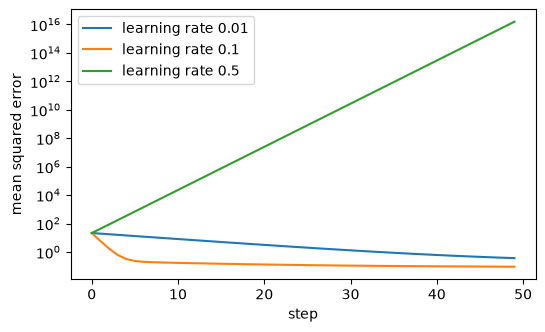

In [23]:
rng = np.random.default_rng(0)
x_line = rng.uniform(0, 2, 100)
y_line = 3 * x_line + 1 + rng.normal(0, 0.3, 100)

def gradient_descent(learning_rate, steps=50):
    w, b, losses = 0.0, 0.0, []
    for _ in range(steps):
        error = w * x_line + b - y_line
        losses.append((error ** 2).mean())
        w -= learning_rate * 2 * (error * x_line).mean()
        b -= learning_rate * 2 * error.mean()
    return w, b, losses

plt.figure(figsize=(6, 3.5))
for learning_rate in [0.01, 0.1, 0.5]:
    w, b, losses = gradient_descent(learning_rate)
    plt.plot(losses, label=f"learning rate {learning_rate}")
    print(f"learning rate {learning_rate}: w = {w:.3g}, b = {b:.3g}, final loss {losses[-1]:.3g}")
plt.yscale("log")
plt.xlabel("step")
plt.ylabel("mean squared error")
plt.legend()
plt.show()

With 0.01 the steps are too small: after 50 steps the line (w = 2.24, b = 1.55) is still far from the true w = 3, b = 1. With 0.1 it gets close (w = 2.85, b = 1.17). With 0.5 every step overshoots further than the last and the weights explode: the loss reaches 10¹⁶. A neural network does exactly this, for thousands of weights at once, with backpropagation computing the gradients.

### A.2 Classical image processing with OpenCV

Before CNNs, computer vision meant hand-designed operations on pixels, and they are still useful for preprocessing. **OpenCV** (`cv2`) is the standard library for them. It reads colour images in blue-green-red order, so convert to RGB before plotting.

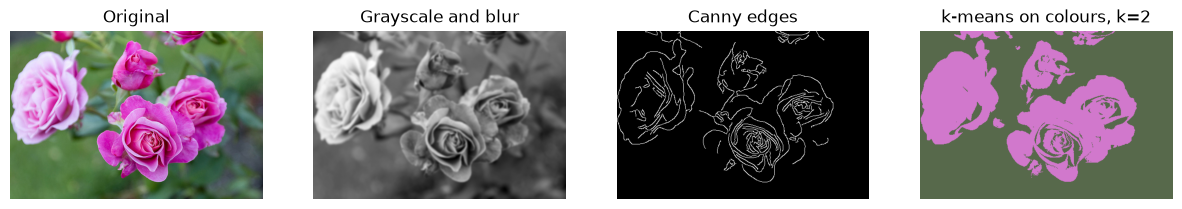

Image shape: (333, 500, 3) - share of pixels in each colour cluster: [0.34344745 0.65655255]


In [24]:
flowers = cv2.cvtColor(cv2.imread("images/flowers.png"), cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(flowers, cv2.COLOR_RGB2GRAY)
blurred = cv2.GaussianBlur(gray, (7, 7), 0)
edges = cv2.Canny(blurred, 50, 150)

pixels = flowers.reshape(-1, 3).astype(float)
kmeans = KMeans(n_clusters=2, n_init=10, random_state=0).fit(pixels)
segmented = kmeans.cluster_centers_[kmeans.labels_].reshape(flowers.shape).astype("uint8")

fig, axes = plt.subplots(1, 4, figsize=(15, 3))
for ax, (title, picture) in zip(axes, [("Original", flowers), ("Grayscale and blur", blurred),
                                       ("Canny edges", edges), ("k-means on colours, k=2", segmented)]):
    ax.imshow(picture, cmap="gray" if picture.ndim == 2 else None)
    ax.set_title(title)
    ax.axis("off")
plt.show()
print("Image shape:", flowers.shape, "- share of pixels in each colour cluster:", np.bincount(kmeans.labels_) / len(kmeans.labels_))

The last panel is Day 3's k-means applied to pixels: every pixel is a row with three features (red, green, blue), and two clusters separate the pink flowers from the green background. The optional **Computer Vision** lab practises these operators.

### A.3 The same models in PyTorch

Keras is used here because it is the shortest way to build and train a network. **PyTorch** is the other major library, and most research code and the Hugging Face models you will meet in Week 7 use it. The concepts are identical: layers, a loss, an optimizer, epochs and batches; PyTorch makes you write the training loop yourself. The notebook `EXTRA Transfer Learning I` in the `s-604` folder of nbs-6 shows transfer learning in PyTorch, and the [PyTorch tutorials](https://pytorch.org/tutorials/beginner/basics/intro.html) cover the basics.